# 04 — Preprocessing and Reproducible Split

**Real data only.** This notebook verifies dataset integrity, documents categorical/numerical representations, defines both target granularities and both feature sets, and reserves the same 20% of students for both tasks.

**Leakage safeguard:** This notebook does **not** fit an encoder/scaler to all data. The learning pipeline is fitted separately inside each training fold in 05 and 06. Selection, hyperparameters and feature-set choices must not be guided by the reserved test set.

In [1]:
from pathlib import Path
import json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
TABLES = ROOT / 'results' / 'tables'
FIGURES = ROOT / 'results' / 'figures'
MODELS = ROOT / 'models'
for p in [TABLES, FIGURES, MODELS, DATA/'processed']:
    p.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
SEVEN_FEATURES = [
    'Average_sleep_duration_per_night',
    'Sleep_quality',
    'Hours_spent_daily_on_academic_activities',
    'Physical_activity_per_week',
    'Use_of_electronic_devices_before_bed',
    'Night_time_caffeine_consumption',
    'Diet_quality'
]
EIGHT_EXTRA_FEATURES = [
    'Overwhelmed_by_academic_workload',
    'Financial_stress_level',
    'Strength_of_social_support',
    'Bedtime_on_regular_nights',
    'Daytime_sleepiness_during_classes',
    'Focus_on_academic_tasks',
    'Type_of_residence',
    'Current_Study_Year'
]
FIFTEEN_FEATURES = SEVEN_FEATURES + EIGHT_EXTRA_FEATURES
TARGET = 'Current_stress_level'
THREE_MAP = {1: 'Low', 2: 'Low', 3: 'Medium', 4: 'High', 5: 'High'}


## 1. Read Dataset 2 and verify completeness

In [2]:
df = pd.read_csv(DATA/'raw'/'dataset2.csv')
assert df.shape == (300,31), f'Unexpected dataset shape: {df.shape}'
assert df[TARGET].isin([1,2,3,4,5]).all()
assert len(SEVEN_FEATURES)==7 and len(FIFTEEN_FEATURES)==15
assert len(set(FIFTEEN_FEATURES))==15
assert all(c in df.columns for c in FIFTEEN_FEATURES)
print('Dataset size:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Exact duplicate rows:', int(df.duplicated().sum()))
display(df[FIFTEEN_FEATURES+[TARGET]].head())


Dataset size: (300, 31)
Missing values: 0
Exact duplicate rows: 0


,Average_sleep_duration_per_night,Sleep_quality,Hours_spent_daily_on_academic_activities,Physical_activity_per_week,Use_of_electronic_devices_before_bed,Night_time_caffeine_consumption,Diet_quality,Overwhelmed_by_academic_workload,Financial_stress_level,Strength_of_social_support,Bedtime_on_regular_nights,Daytime_sleepiness_during_classes,Focus_on_academic_tasks,Type_of_residence,Current_Study_Year,Current_stress_level
0,5-6 hrs,Good,>4 hrs,Moderate,Yes,Yes,Average,Never,1,High,After 12 AM,Rarely,Always,On-Campus,3,5
1,<5 hrs,Average,1-2 hrs,Low,Yes,Yes,Good,Rarely,4,Moderate,After 12 AM,Often,Rarely,Off-Campus,3,1
2,7-8 hrs,Poor,3-4 hrs,Low,No,No,Average,Often,1,High,After 12 AM,Never,Sometimes,Off-Campus,2,5
3,5-6 hrs,Poor,3-4 hrs,High,Yes,No,Poor,Sometimes,1,Moderate,After 12 AM,Rarely,Often,With Family,3,5
4,5-6 hrs,Average,<1 hrs,Moderate,Yes,Yes,Good,Never,3,High,After 12 AM,Rarely,Always,Off-Campus,4,3


## 2. Column types, category values, and anomalies

In [3]:
audit = pd.DataFrame({
 'feature':FIFTEEN_FEATURES,
 'dtype':[str(df[c].dtype) for c in FIFTEEN_FEATURES],
 'unique_values':[df[c].nunique(dropna=False) for c in FIFTEEN_FEATURES],
 'missing':[int(df[c].isna().sum()) for c in FIFTEEN_FEATURES],
 'examples':[', '.join(map(str, df[c].dropna().unique()[:7])) for c in FIFTEEN_FEATURES]
})
display(audit)
audit.to_csv(TABLES/'preprocessing_audit.csv',index=False)
print('Financial stress values:',sorted(df['Financial_stress_level'].unique().tolist()))
print('Study year values:',sorted(df['Current_Study_Year'].unique().tolist()))
assert df['Financial_stress_level'].between(1,5).all()
assert df['Current_Study_Year'].between(1,4).all()


,feature,dtype,unique_values,missing,examples
0,Average_sleep_duration_per_night,object,4,0,"5-6 hrs, <5 hrs, 7-8 hrs, >8 hrs"
1,Sleep_quality,object,3,0,"Good, Average, Poor"
2,Hours_spent_daily_on_academic_activities,object,5,0,">4 hrs, 1-2 hrs, 3-4 hrs, <1 hrs, 2-3 hrs"
3,Physical_activity_per_week,object,3,0,"Moderate, Low, High"
4,Use_of_electronic_devices_before_bed,object,2,0,"Yes, No"
5,Night_time_caffeine_consumption,object,2,0,"Yes, No"
6,Diet_quality,object,3,0,"Average, Good, Poor"
7,Overwhelmed_by_academic_workload,object,5,0,"Never, Rarely, Often, Sometimes, Always"
8,Financial_stress_level,int64,5,0,"1, 4, 3, 5, 2"
9,Strength_of_social_support,object,3,0,"High, Moderate, Low"


Financial stress values: [1, 2, 3, 4, 5]
Study year values: [1, 2, 3, 4]


## 3. Numerical outliers and target distribution

The two numeric predictors in our expanded features are **bounded, discrete response scales**. IQR flags are descriptive only; values within the documented scales should not be removed just because they are uncommon. Other input features are categorical responses and do not warrant numerical outlier deletion.

Financial_stress_level: min=1, max=5, IQR flags=0 (not automatically removed)
Current_Study_Year: min=1, max=4, IQR flags=0 (not automatically removed)


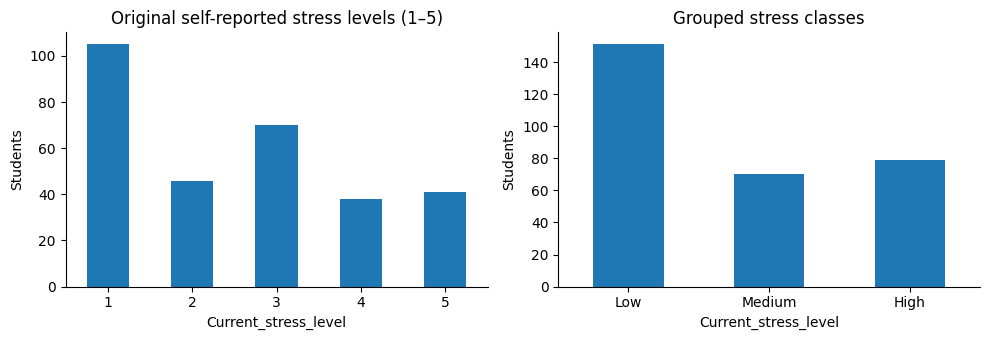

5-class distribution:


Current_stress_level
1    105
2     46
3     70
4     38
5     41
Name: count, dtype: int64

3-class distribution:


Current_stress_level
Low       151
Medium     70
High       79
Name: count, dtype: int64

In [4]:
for feature in ['Financial_stress_level','Current_Study_Year']:
    s = df[feature]
    q1,q3=s.quantile([0.25,0.75]); iqr=q3-q1
    flags=((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum()
    print(f'{feature}: min={s.min()}, max={s.max()}, IQR flags={flags} (not automatically removed)')

labels3=df[TARGET].map(THREE_MAP)
fig, axs=plt.subplots(1,2,figsize=(10,3.5))
df[TARGET].value_counts().sort_index().plot(kind='bar',ax=axs[0],title='Original self-reported stress levels (1–5)')
labels3.value_counts().reindex(['Low','Medium','High']).plot(kind='bar',ax=axs[1],title='Grouped stress classes')
for ax in axs:ax.set_ylabel('Students');ax.tick_params(axis='x',rotation=0)
plt.tight_layout();plt.show()
print('5-class distribution:');display(df[TARGET].value_counts().sort_index())
print('3-class distribution:');display(labels3.value_counts().reindex(['Low','Medium','High']))


## 4. Save cleaned data and one fixed train/test membership

No missing values or exact duplicates require deletion. We preserve all 300 real students. Stratification uses the original five-level label so both tasks share exactly the same students in the test set. `Q Number` is a row identifier and **never** an input feature.

In [5]:
from sklearn.model_selection import train_test_split
idx=np.arange(len(df))
train_idx,test_idx=train_test_split(idx,test_size=.20,stratify=df[TARGET],random_state=RANDOM_STATE)
assert len(train_idx)==240 and len(test_idx)==60
assert len(set(train_idx)&set(test_idx))==0
# Preserve original order and an explicit row-id split for all subsequent notebooks.
split=pd.DataFrame({'row_index':np.arange(len(df)), 'split':['test' if i in set(test_idx) else 'train' for i in range(len(df))]})
split.to_csv(DATA/'processed'/'split_indices.csv',index=False)
df.to_csv(DATA/'processed'/'dataset2_cleaned.csv',index=False)
meta={'seven_features': SEVEN_FEATURES, 'fifteen_features':FIFTEEN_FEATURES,
      'target':TARGET, 'three_class_mapping':{str(k):v for k,v in THREE_MAP.items()},
      'random_state':RANDOM_STATE,'split_file':'data/processed/split_indices.csv',
      'training_rows':len(train_idx),'test_rows':len(test_idx),
      'note':'Existing survey data; no synthetic records. Test set was viewed in earlier exploratory work.'}
(DATA/'processed'/'experiment_config.json').write_text(json.dumps(meta,indent=2),encoding='utf-8')
print('Train/test:',len(train_idx),len(test_idx))
print('5-class train/test distributions:')
display(pd.crosstab(split['split'], df[TARGET]))
print('3-class train/test distributions:')
display(pd.crosstab(split['split'],labels3))
print('Saved reproducible split and configuration.')


Train/test: 240 60
5-class train/test distributions:


Current_stress_level,1,2,3,4,5
split,,,,,
test,21,9,14,8,8
train,84,37,56,30,33


3-class train/test distributions:


Current_stress_level,High,Low,Medium
split,,,
test,16,30,14
train,63,121,56


Saved reproducible split and configuration.


## 5. Model-ready input conventions

- 7 features: lifestyle and academic-activity measures specified in the original proposal.
- 15 features: the same 7 plus 8 academic, social, environmental and demographic measures.
- `Current_stress_level` is the survey-reported outcome, **never** a predictor.
- Bounded numeric responses are scaled; nominal survey categories are one-hot encoded within CV pipelines.
- No SMOTE or synthetic records. No transformations were learned from the held-out test set.
- Repeated examination of this dataset and the earlier 20% split means the final holdout should be presented as **exploratory** rather than fully independent external validation.